BFS Path: ['A', 'C', 'F']


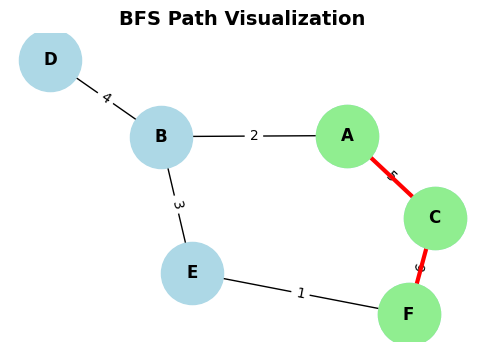

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

# Graph Definition
graph = {
    'A': {'B': 2, 'C': 5}, 'B': {'A': 2, 'D': 4, 'E': 3},
    'C': {'A': 5, 'F': 6}, 'D': {'B': 4},
    'E': {'B': 3, 'F': 1}, 'F': {'C': 6, 'E': 1}
}

def visualize_search(graph, path, title):
    G = nx.Graph()
    for node, edges in graph.items():
        for adj, weight in edges.items():
            G.add_edge(node, adj, weight=weight)
    pos = nx.spring_layout(G)
    plt.figure(figsize=(6, 4))
    plt.title(title, fontsize=14, fontweight='bold')
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_weight='bold')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'))

    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=3)
        nx.draw_networkx_nodes(G, pos, nodelist=path, node_color='lightgreen', node_size=2000)
    plt.show()

# BFS Algorithm
def bfs(graph, start, goal):
    queue = deque([[start]])
    visited = set([start])
    while queue:
        path = queue.popleft()
        node = path[-1]
        if node == goal: return path
        for adjacent in graph.get(node, []):
            if adjacent not in visited:
                visited.add(adjacent)
                queue.append(path + [adjacent])
    return []

# Run & Visualize
path = bfs(graph, 'A', 'F')
print("BFS Path:", path)
visualize_search(graph, path, "BFS Path Visualization")
